<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>DIRGA ALIN CRISTIN RERO</span><span>(H061241016)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>

## **Analisis Hasil Pemodelan Sintetik 1D (R-CS-004) pada Studi Kasus Reservoar Gas**

Pemodelan gelombang seismik sintetik 1D berbasis forward modeling dilakukan untuk merepresentasikan respons seismik dari empat lapisan batuan dengan parameter kecepatan dan densitas yang berbeda. Pada panel profil kecepatan, terlihat perubahan nilai (V_p) dan (V_s) pada setiap batas lapisan. Lapisan low-velocity shale memiliki (V_p) sebesar 2.500 m/s, sedangkan lapisan gas-bearing sandstone memiliki (V_p) sebesar 3.600 m/s. Oleh karena itu, parameter yang digunakan menunjukkan peningkatan kecepatan gelombang P pada batas atas batupasir, disertai perubahan kecepatan gelombang S dan densitas batuan.
Perubahan parameter tersebut menghasilkan kontras impedansi akustik yang digunakan untuk menghitung reflektivitas pada batas antarlapisan. Reflektivitas kemudian dikonvolusikan dengan Ricker wavelet berfrekuensi 30 Hz untuk membentuk jejak gelombang P dan S sintetik. Pada panel impedansi akustik, perbedaan nilai impedansi antarlapisan menggambarkan perubahan sifat fisik model. Sementara itu, panel P-Wave Synthetic menampilkan respons amplitudo yang dihasilkan oleh kontras impedansi pada Horizon C di waktu 0,15 detik dan pada kontak air-gas di waktu 0,25 detik.

RECIPE R-CS-004
SYNTHETIC SEISMIC-WAVE REFERENCE IMPLEMENTATION
Interval sampling: 0.001 s
Durasi model: 0.40 s
Jumlah sampel: 400
Frekuensi Ricker wavelet: 30.0 Hz
Horizon C: 0.15 s
Gas-Water Contact: 0.25 s

Parameter lapisan:
------------------------------------------------------------
Lapisan                      Vp (m/s)    Vs (m/s)    Densitas
------------------------------------------------------------
Top Shale                        3400        1800        2.40
Low-Velocity Shale               2500        1300        2.20
Gas-Bearing Sandstone            3600        2400        2.10
Water Sandstone                  4200        2400        2.35


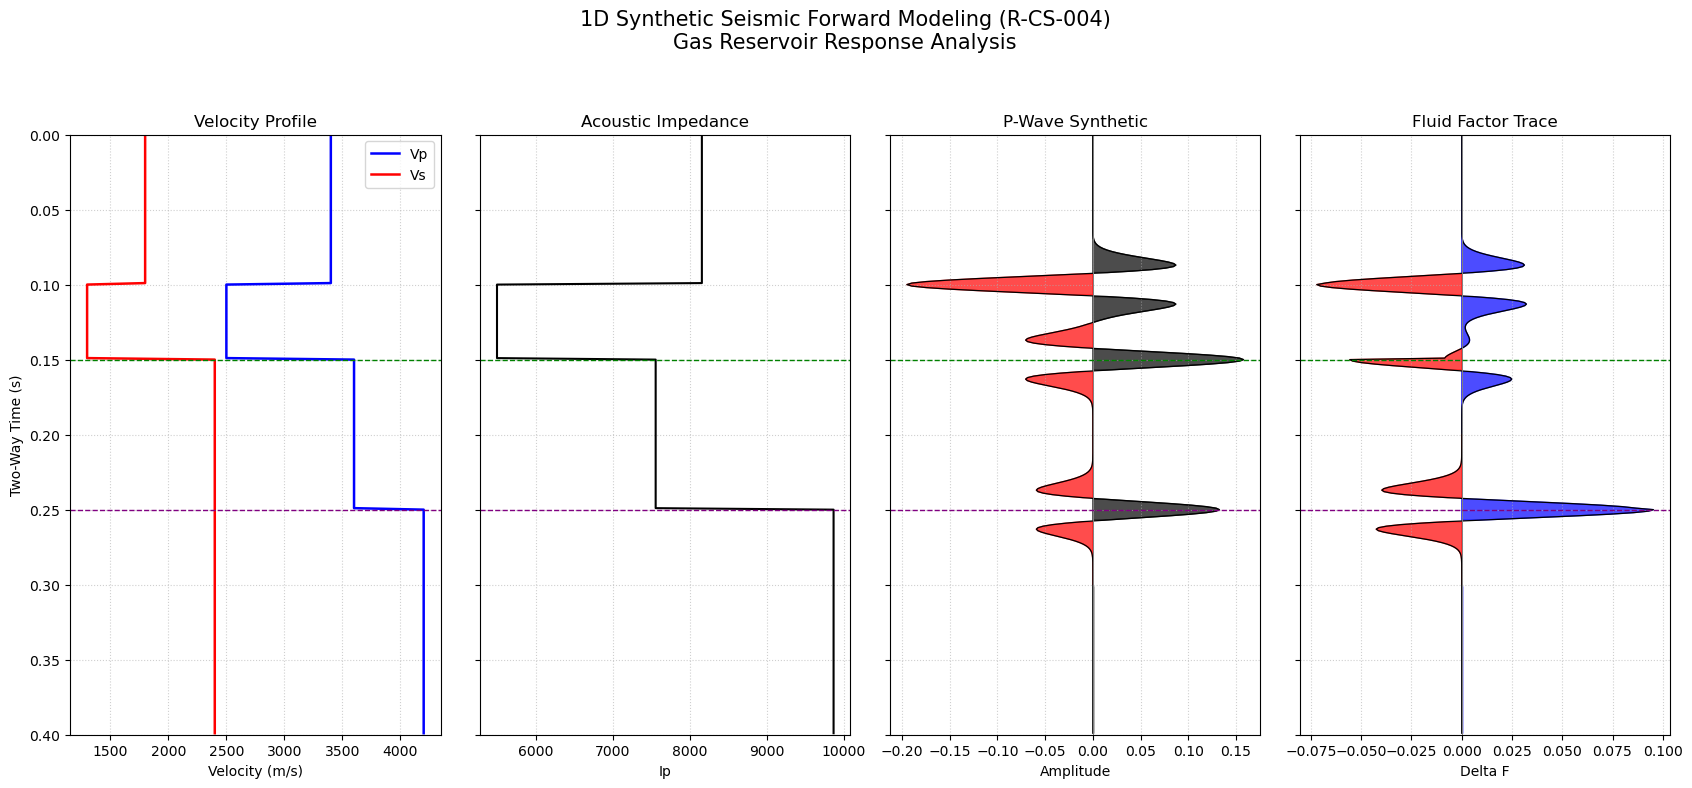


Grafik berhasil dibuat.
Lokasi grafik: D:\KULIAH\Semester 5\Kecerdasan Artifisial\Hasil_R_CS_004\R_CS_004_Synthetic_Seismic.png


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. PENGATURAN OUTPUT
# ============================================================

OUTPUT_DIR = Path("Hasil_R_CS_004")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. PARAMETER WAKTU
# ============================================================

dt = 0.001
t_max = 0.4
time = np.arange(0, t_max, dt)

# Inisialisasi parameter batuan
vp = np.zeros_like(time)
vs = np.zeros_like(time)
rho = np.zeros_like(time)

# ============================================================
# 3. MODEL LAPISAN BATUAN
# ============================================================

# Lapisan 1: Top Shale (0.00-0.10 s)
mask1 = (time >= 0.00) & (time < 0.10)
vp[mask1] = 3400.0
vs[mask1] = 1800.0
rho[mask1] = 2.40

# Lapisan 2: Low-Velocity Shale (0.10-0.15 s)
mask2 = (time >= 0.10) & (time < 0.15)
vp[mask2] = 2500.0
vs[mask2] = 1300.0
rho[mask2] = 2.20

# Lapisan 3: Gas-Bearing Sandstone (0.15-0.25 s)
mask3 = (time >= 0.15) & (time < 0.25)
vp[mask3] = 3600.0
vs[mask3] = 2400.0
rho[mask3] = 2.10

# Lapisan 4: Water Sandstone (0.25-0.40 s)
mask4 = (time >= 0.25) & (time < 0.40)
vp[mask4] = 4200.0
vs[mask4] = 2400.0
rho[mask4] = 2.35

# ============================================================
# 4. PERHITUNGAN IMPEDANSI
# ============================================================

Ip = vp * rho
Is = vs * rho

# ============================================================
# 5. PERHITUNGAN REFLEKTIVITAS
# ============================================================

Rp = np.zeros_like(time)
Rs = np.zeros_like(time)

for i in range(1, len(time)):
    if Ip[i] != Ip[i - 1] and Ip[i - 1] != 0:
        Rp[i] = (
            (Ip[i] - Ip[i - 1])
            / (Ip[i] + Ip[i - 1])
        )

    if Is[i] != Is[i - 1] and Is[i - 1] != 0:
        Rs[i] = (
            (Is[i] - Is[i - 1])
            / (Is[i] + Is[i - 1])
        )

# ============================================================
# 6. PEMBUATAN RICKER WAVELET
# ============================================================

f0 = 30.0
tw = 0.05

wavelet_time = np.arange(-tw, tw + dt, dt)

ricker = (
    1 - 2 * (np.pi * f0 * wavelet_time) ** 2
) * np.exp(
    -(np.pi * f0 * wavelet_time) ** 2
)

# ============================================================
# 7. SEISMIK SINTETIK
# ============================================================

p_wave_synth = np.convolve(
    Rp, ricker, mode="same"
)

s_wave_synth = np.convolve(
    Rs, ricker, mode="same"
)

# ============================================================
# 8. PERHITUNGAN FLUID FACTOR
# ============================================================

rasio_vs_vp = np.divide(
    vs,
    vp,
    out=np.zeros_like(vs),
    where=vp != 0
)

gain_g = 1.16 * rasio_vs_vp

fluid_factor_synth = (
    p_wave_synth
    - gain_g * s_wave_synth
)

# ============================================================
# 9. INFORMASI MODEL
# ============================================================

print("=" * 60)
print("RECIPE R-CS-004")
print("SYNTHETIC SEISMIC-WAVE REFERENCE IMPLEMENTATION")
print("=" * 60)

print(f"Interval sampling: {dt:.3f} s")
print(f"Durasi model: {t_max:.2f} s")
print(f"Jumlah sampel: {len(time)}")
print(f"Frekuensi Ricker wavelet: {f0:.1f} Hz")
print("Horizon C: 0.15 s")
print("Gas-Water Contact: 0.25 s")

print("\nParameter lapisan:")
print("-" * 60)
print(
    f"{'Lapisan':<25}"
    f"{'Vp (m/s)':>12}"
    f"{'Vs (m/s)':>12}"
    f"{'Densitas':>12}"
)

print("-" * 60)
print(f"{'Top Shale':<25}{3400:>12}{1800:>12}{2.40:>12.2f}")
print(f"{'Low-Velocity Shale':<25}{2500:>12}{1300:>12}{2.20:>12.2f}")
print(f"{'Gas-Bearing Sandstone':<25}{3600:>12}{2400:>12}{2.10:>12.2f}")
print(f"{'Water Sandstone':<25}{4200:>12}{2400:>12}{2.35:>12.2f}")

# ============================================================
# 10. VISUALISASI EMPAT PANEL
# ============================================================

fig, axes = plt.subplots(
    1, 4,
    figsize=(17, 8),
    sharey=True
)

# Panel 1: Profil kecepatan
ax = axes[0]

ax.plot(vp, time, color="blue", linewidth=1.8, label="Vp")
ax.plot(vs, time, color="red", linewidth=1.8, label="Vs")

ax.set_title("Velocity Profile")
ax.set_xlabel("Velocity (m/s)")
ax.set_ylabel("Two-Way Time (s)")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
ax.invert_yaxis()

# Panel 2: Impedansi akustik
ax = axes[1]

ax.plot(Ip, time, color="black", linewidth=1.5)

ax.set_title("Acoustic Impedance")
ax.set_xlabel("Ip")
ax.grid(True, linestyle=":", alpha=0.6)

# Panel 3: P-Wave Synthetic
ax = axes[2]

ax.plot(
    p_wave_synth,
    time,
    color="black",
    linewidth=0.9
)

ax.fill_betweenx(
    time,
    0,
    p_wave_synth,
    where=p_wave_synth >= 0,
    color="black",
    alpha=0.7
)

ax.fill_betweenx(
    time,
    0,
    p_wave_synth,
    where=p_wave_synth < 0,
    color="red",
    alpha=0.7
)

ax.axvline(0, color="gray", linewidth=0.7)
ax.set_title("P-Wave Synthetic")
ax.set_xlabel("Amplitude")
ax.grid(True, linestyle=":", alpha=0.6)

# Panel 4: Fluid Factor
ax = axes[3]

ax.plot(
    fluid_factor_synth,
    time,
    color="black",
    linewidth=0.9
)

ax.fill_betweenx(
    time,
    0,
    fluid_factor_synth,
    where=fluid_factor_synth >= 0,
    color="blue",
    alpha=0.7
)

ax.fill_betweenx(
    time,
    0,
    fluid_factor_synth,
    where=fluid_factor_synth < 0,
    color="red",
    alpha=0.7
)

ax.axvline(0, color="gray", linewidth=0.7)
ax.set_title("Fluid Factor Trace")
ax.set_xlabel("Delta F")
ax.grid(True, linestyle=":", alpha=0.6)

# ============================================================
# 11. PENANDA HORIZON
# ============================================================

for ax in axes:
    ax.axhline(
        0.15,
        color="green",
        linestyle="--",
        linewidth=1.0
    )

    ax.axhline(
        0.25,
        color="purple",
        linestyle="--",
        linewidth=1.0
    )

    ax.set_ylim(0.40, 0.00)

fig.suptitle(
    "1D Synthetic Seismic Forward Modeling (R-CS-004)\n"
    "Gas Reservoir Response Analysis",
    fontsize=15
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

# ============================================================
# 12. SIMPAN DAN TAMPILKAN GRAFIK
# ============================================================

output_png = OUTPUT_DIR / "R_CS_004_Synthetic_Seismic.png"

fig.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGrafik berhasil dibuat.")
print(f"Lokasi grafik: {output_png.resolve()}")

Model menghasilkan profil kecepatan batuan, impedansi akustik, reflektivitas, jejak gelombang P, dan Fluid Factor. Visualisasi empat panel membantu memperlihatkan respons model pada batas antarlapisan, termasuk Horizon C dan kontak air-gas. Praktik ini menunjukkan bahwa parameter fisik batuan berperan dalam membentuk respons seismik sintetik, tetapi identifikasi reservoar gas tetap memerlukan interpretasi yang mempertimbangkan asumsi model dan data pendukung.

## **Case Study: Model Panas Bawah Permukaan Berlapis dengan Seasonal Forcing**

PARAMETER MODEL TERMAL
Temperatur rata-rata : 25.00 °C
Amplitudo musiman    : 5.00 °C
Periode              : 365 hari
Difusivitas termal   : 1.00e-06 m²/s
Kedalaman redaman    : 3.17 m


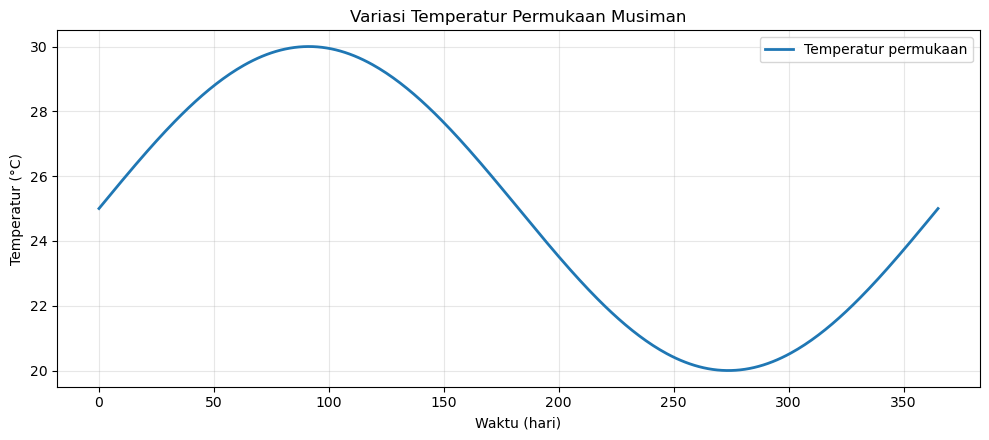

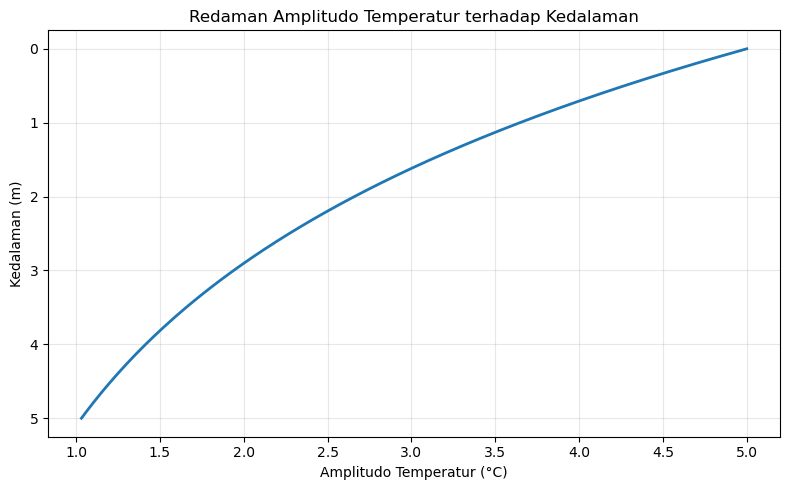

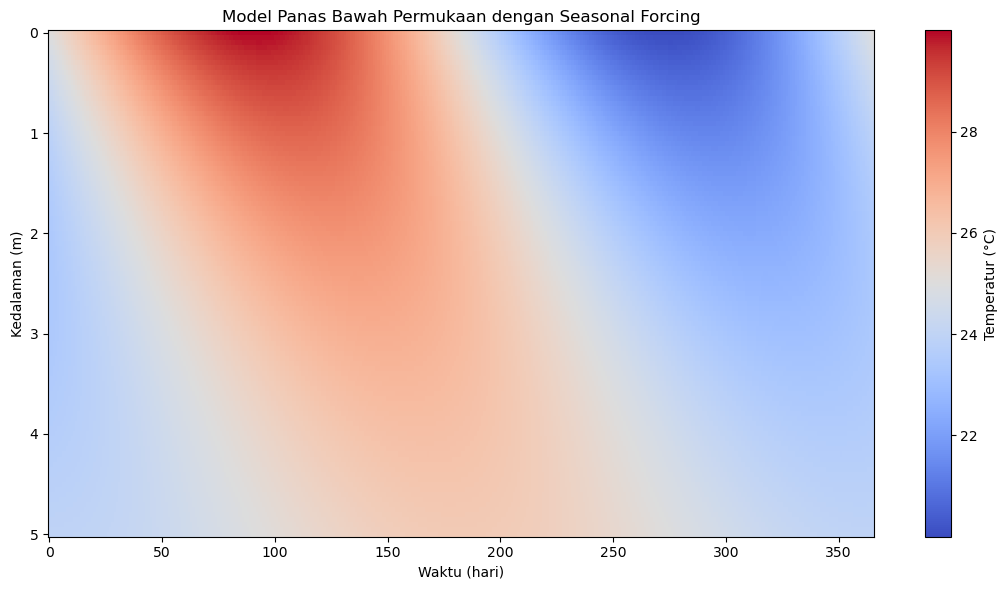

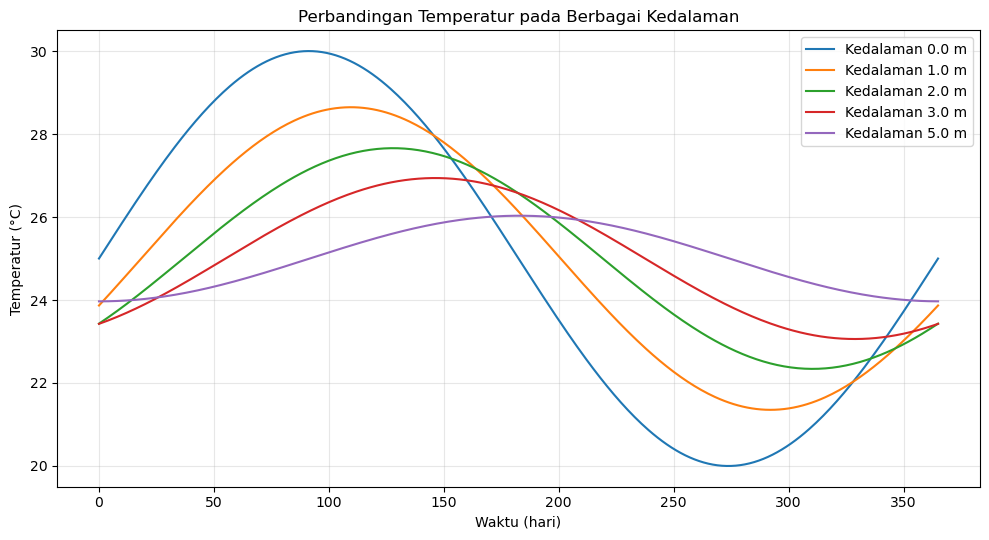


RINGKASAN HASIL SIMULASI
Kedalaman   0 m | Amplitudo = 5.000 °C | Keterlambatan fase = 0.00 hari
Kedalaman   1 m | Amplitudo = 3.647 °C | Keterlambatan fase = 18.34 hari
Kedalaman   2 m | Amplitudo = 2.660 °C | Keterlambatan fase = 36.67 hari
Kedalaman   3 m | Amplitudo = 1.940 °C | Keterlambatan fase = 55.01 hari
Kedalaman   5 m | Amplitudo = 1.032 °C | Keterlambatan fase = 91.68 hari

Semua grafik tersimpan di: D:\KULIAH\Semester 5\Kecerdasan Artifisial\Hasil_R_MOD_002


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. PARAMETER MODEL
# ==================================================
OUTPUT_DIR = Path("Hasil_R_MOD_002")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

T_mean = 25.0          # Temperatur rata-rata permukaan (°C)
delta_T = 5.0          # Amplitudo temperatur musiman (°C)
P_days = 365.0         # Periode tahunan (hari)

# Difusivitas termal tanah (m²/s)
kappa = 1.0e-6

# Konversi periode dari hari ke detik
P_seconds = P_days * 24 * 3600

# Kedalaman redaman termal (m)
delta = np.sqrt(kappa * P_seconds / np.pi)

print("PARAMETER MODEL TERMAL")
print(f"Temperatur rata-rata : {T_mean:.2f} °C")
print(f"Amplitudo musiman    : {delta_T:.2f} °C")
print(f"Periode              : {P_days:.0f} hari")
print(f"Difusivitas termal   : {kappa:.2e} m²/s")
print(f"Kedalaman redaman    : {delta:.2f} m")

# ==================================================
# 2. DOMAIN WAKTU DAN KEDALAMAN
# ==================================================
waktu_hari = np.linspace(0, P_days, 366)
kedalaman = np.linspace(0, 5, 101)

T, Z = np.meshgrid(waktu_hari, kedalaman)

# ==================================================
# 3. MODEL TEMPERATUR BAWAH PERMUKAAN
# ==================================================
# Model konduksi panas periodik:
# amplitudo berkurang secara eksponensial
# dan fase terlambat sebanding dengan kedalaman.

amplitudo = delta_T * np.exp(-Z / delta)

fase = (2 * np.pi * T / P_days) - (Z / delta)

temperatur = T_mean + amplitudo * np.sin(fase)

# Temperatur permukaan
temperatur_permukaan = (
    T_mean
    + delta_T * np.sin(2 * np.pi * waktu_hari / P_days)
)

# ==================================================
# 4. GRAFIK TEMPERATUR PERMUKAAN
# ==================================================
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    waktu_hari,
    temperatur_permukaan,
    linewidth=2,
    label="Temperatur permukaan"
)

ax.set_title("Variasi Temperatur Permukaan Musiman")
ax.set_xlabel("Waktu (hari)")
ax.set_ylabel("Temperatur (°C)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "Temperatur_Permukaan.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==================================================
# 5. GRAFIK REDAMAN AMPLITUDO
# ==================================================
kedalaman_1d = np.linspace(0, 5, 200)
amplitudo_1d = delta_T * np.exp(-kedalaman_1d / delta)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(amplitudo_1d, kedalaman_1d, linewidth=2)

ax.set_title("Redaman Amplitudo Temperatur terhadap Kedalaman")
ax.set_xlabel("Amplitudo Temperatur (°C)")
ax.set_ylabel("Kedalaman (m)")
ax.invert_yaxis()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "Redaman_Termal.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==================================================
# 6. HEATMAP TEMPERATUR BAWAH PERMUKAAN
# ==================================================
fig, ax = plt.subplots(figsize=(11, 6))

gambar = ax.pcolormesh(
    waktu_hari,
    kedalaman,
    temperatur,
    shading="auto",
    cmap="coolwarm"
)

ax.set_title("Model Panas Bawah Permukaan dengan Seasonal Forcing")
ax.set_xlabel("Waktu (hari)")
ax.set_ylabel("Kedalaman (m)")
ax.invert_yaxis()

cbar = plt.colorbar(gambar, ax=ax)
cbar.set_label("Temperatur (°C)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "Heatmap_Temperatur.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==================================================
# 7. PERBANDINGAN TEMPERATUR ANTAR KEDALAMAN
# ==================================================
kedalaman_pilihan = [0, 1, 2, 3, 5]

fig, ax = plt.subplots(figsize=(10, 5.5))

for z0 in kedalaman_pilihan:
    indeks = np.argmin(np.abs(kedalaman - z0))

    ax.plot(
        waktu_hari,
        temperatur[indeks, :],
        label=f"Kedalaman {kedalaman[indeks]:.1f} m"
    )

ax.set_title("Perbandingan Temperatur pada Berbagai Kedalaman")
ax.set_xlabel("Waktu (hari)")
ax.set_ylabel("Temperatur (°C)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "Perbandingan_Kedalaman.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ==================================================
# 8. RINGKASAN HASIL
# ==================================================
print("\nRINGKASAN HASIL SIMULASI")

for z0 in kedalaman_pilihan:
    amp_z = delta_T * np.exp(-z0 / delta)
    lag_hari = (z0 / delta) * P_days / (2 * np.pi)

    print(
        f"Kedalaman {z0:>3} m | "
        f"Amplitudo = {amp_z:.3f} °C | "
        f"Keterlambatan fase = {lag_hari:.2f} hari"
    )

print(f"\nSemua grafik tersimpan di: {OUTPUT_DIR.resolve()}")


Pemodelan panas bawah permukaan berlapis dengan seasonal forcing dapat menggambarkan pengaruh variasi temperatur musiman terhadap kondisi termal pada kedalaman yang berbeda. Simulasi menunjukkan dua karakteristik utama, yaitu redaman amplitudo secara eksponensial dan keterlambatan fase terhadap perubahan temperatur permukaan.

Python dapat digunakan untuk menghitung dan memvisualisasikan kedua fenomena tersebut melalui grafik temperatur permukaan, grafik redaman amplitudo, heatmap temperatur, serta perbandingan temperatur pada beberapa kedalaman. Model ini memberikan gambaran dasar mengenai perpindahan panas periodik di bawah permukaan bumi.